<a href="https://colab.research.google.com/github/ruforavishnu/Project_Machine_Learning/blob/master/Project22_Reinforcement_Learning_Autonomous_car_parking_dqn_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install numpy matplotlib torch


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from collections import deque

import torch
import torch.nn as nn
import torch.optim as optim

print("All libraries imported successfully!")

print("PyTorch version:", torch.__version__)
print("NumPy version:", np.__version__)
print("CUDA available:", torch.cuda.is_available())

All libraries imported successfully!
PyTorch version: 2.11.0+cpu
NumPy version: 2.1.3
CUDA available: False


In [4]:
PARKING_WIDTH = 10
PARKING_HEIGHT = 10

TARGET_X = 7.0
TARGET_Y = 7.0
TARGET_ANGLE = 0.0

CAR_LENGTH = 1.0
CAR_WIDTH = 0.5

MOVE_STEP = 0.2
TURN_STEP = math.radians(15)

print('Parking environment configured')
print('Parking area:', PARKING_WIDTH, 'x', PARKING_HEIGHT)
print('Target position:', TARGET_X, ',', TARGET_Y)
print('Target angle:', TARGET_ANGLE)
print('Car length:', CAR_LENGTH)
print('Car width:', CAR_WIDTH)



Parking environment configured
Parking area: 10 x 10
Target position: 7.0 , 7.0
Target angle: 0.0
Car length: 1.0
Car width: 0.5


In [11]:
class ParkingEnv:
  def __init__(self):
    self.height = PARKING_HEIGHT
    self.width = PARKING_WIDTH

    self.target_x = TARGET_X
    self.target_y = TARGET_Y
    self.target_angle = TARGET_ANGLE

    self.car_length = CAR_LENGTH
    self.car_width = CAR_WIDTH

    self.move_step = MOVE_STEP
    self.turn_step = TURN_STEP

    self.reset()

  def reset(self):
    self.x = 2.0
    self.y = 2.0
    self.angle = 0.0

    return self.get_state()

  def get_state(self):
    return np.array([self.x, self.y, self.angle],   dtype=np.float32)


  def step(self, action):

    if action == 0:
      self.x += self.move_step * math.cos(self.angle)
      self.y += self.move_step * math.sin(self.angle)
    elif action == 1:
      self.angle -= self.move_step * math.cos(self.angle)
      self.angle -= self.move_step * math.sin(self.angle)
    elif action == 2:
      self.angle += self.turn_step

    elif action == 3:
      self.angle -= self.turn_step

    elif action == 4:
      pass

    else:
      raise ValueError('Invalid Action!')


    self.angle = ( (self.angle + math.pi ) % (2*math.pi)   - math.pi)

    return self.get_state()

  def get_car_corners(self):
    length = self.car_length / 2
    width = self.car_width / 2


    local_corners = np.array([
      [-length, -width],
      [length, -width],
      [length, width],
      [-length, width]
    ])

    rotation = np.array([
      [math.cos(self.angle), -math.sin(self.angle)],
      [math.sin(self.angle), math.cos(self.angle)]
    ])

    rotated = local_corners  @ rotation.T

    return rotated + np.array([self.x, self.y])



  def render(self):
    fig, ax = plt.subplots()
    ax.set_xlim(0, self.width)
    ax.set_ylim(0, self.height)

    ax.set_aspect('equal')
    ax.set_xticks(np.arange(0, self.width + 1, 1))
    ax.set_yticks(np.arange(0, self.height + 1, 1))

    ax.grid(True, alpha = 0.3)


    target = plt.Rectangle( (self.target_x - 0.8,   self.target_y - 0.8),   1.6, 1.6,  fill=False,  edgecolor='green', linewidth =3)

    ax.add_patch(target)

    ax.scatter(self.target_x,  self.target_y,    marker='x',  s=100,  label='Target')


    car = plt.Polygon(self.get_car_corners(),  fill=False,  edgecolor='red', linewidth =3)

    ax.add_patch(car)


    ax.arrow(self.x,  self.y,  0.7 * math.cos(self.angle),  0.7* math.sin(self.angle),  head_width=0.2,  head_length=0.2   , color='black')


    ax.set_title('Autonomous Car Parking Environment')
    ax.set_xlabel('X Position')
    ax.set_ylabel('Y Position')
    ax.legend(loc='upper left')
    plt.show()

Initial car state: [2. 2. 0.]


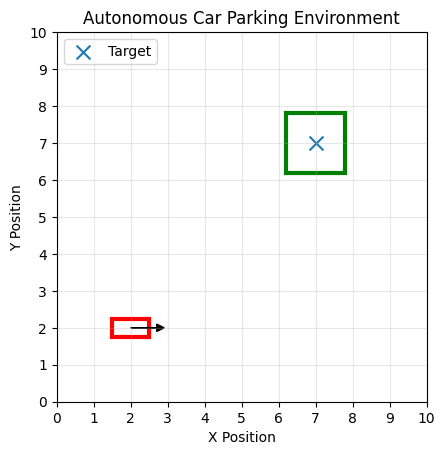

In [12]:
env = ParkingEnv()


initial_state = env.reset()

print('Initial car state:', initial_state)

env.render()